# ✍️ Handwritten Digit + Letter Recognition (ek hi CNN se)
**Domain:** Education / OCR | **Skill:** CNN | **Dataset:** MNIST (digits) + EMNIST Letters (tensorflow_datasets)

**Idea:** Ek **single model** jo 36 classes pehchanta hai: `0-9` (digits) aur `A-Z` (letters). Webcam me mode badalne ki zarurat nahi, model khud bata dega ki digit hai ya letter.

**Plan:**
1. MNIST se digits load karo
2. EMNIST se letters load karo (tfds)
3. Dono ko milao (36 classes), ek CNN train karo
4. Webcam pe live demo

## Step 0: Libraries import karna
**Kya hua:** Jo tools chahiye wo load kiye (TensorFlow = deep learning, tfds = dataset downloader, OpenCV = webcam).
Pehli baar ho to neeche `!pip` line se `#` hata ke ek baar run karo.

In [2]:
# !pip install tensorflow tensorflow-datasets opencv-python matplotlib numpy scikit-learn seaborn

import string
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


# PART A: MNIST (Digits 0–9)

## Step 1: MNIST load karna
**Kya hua:** Keras me MNIST built-in hai.
- 60,000 train + 10,000 test images
- 28x28 pixels, grayscale
- Label = 0 se 9

In [3]:
(x_train_d, y_train_d), (x_test_d, y_test_d) = keras.datasets.mnist.load_data()

print("Digit Training Images:", x_train_d.shape)
print("Digit Training Labels:", y_train_d.shape)

print("Digit Testing Images:", x_test_d.shape)
print("Digit Testing Labels:", y_test_d.shape)

Digit Training Images: (60000, 28, 28)
Digit Training Labels: (60000,)
Digit Testing Images: (10000, 28, 28)
Digit Testing Labels: (10000,)


## Step 2: Digits ke samples dekhna
**Kya hua:** Pehle 10 images aur label dikhaye, taaki data samajh aaye.

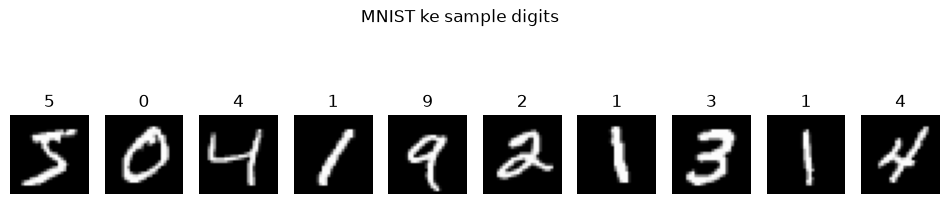

In [4]:
plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_train_d[i], cmap="gray")
    plt.title(y_train_d[i])
    plt.axis("off")
plt.suptitle("MNIST ke sample digits")
plt.show()

# PART B: EMNIST Letters (A–Z) via tensorflow_datasets

## Step 3: EMNIST letters load karna
**Kya hua:** `tfds.load` se EMNIST letters khud download ho jata hai (pehli baar ~500MB, thoda time lagega, internet chahiye).
- `split=['train', 'test']` = train aur test dono mile
- `as_supervised=True` = (image, label) ke jodi me data
- Letters ke label **1 se 26** hote hain (1 = A, 26 = Z)

In [5]:
(ds_train, ds_test), info = tfds.load(
    'emnist/letters',
    split=['train', 'test'],
    as_supervised=True,
    with_info=True
)

print("Letters train examples:", info.splits['train'].num_examples)
print("Letters test examples :", info.splits['test'].num_examples)

Letters train examples: 88800
Letters test examples : 14800


## Step 4: Letters ke samples dekhna (A–Z)
**Kya hua:** Pehle 26 images nikal ke dikhayi.

**Zaruri baat:** EMNIST ki images asal me **side se ulti (transposed)** store hoti hain. Isliye `.T` lagaya, jisse letter seedha dikhe. Wahi fix aage poore data pe bhi lagega.

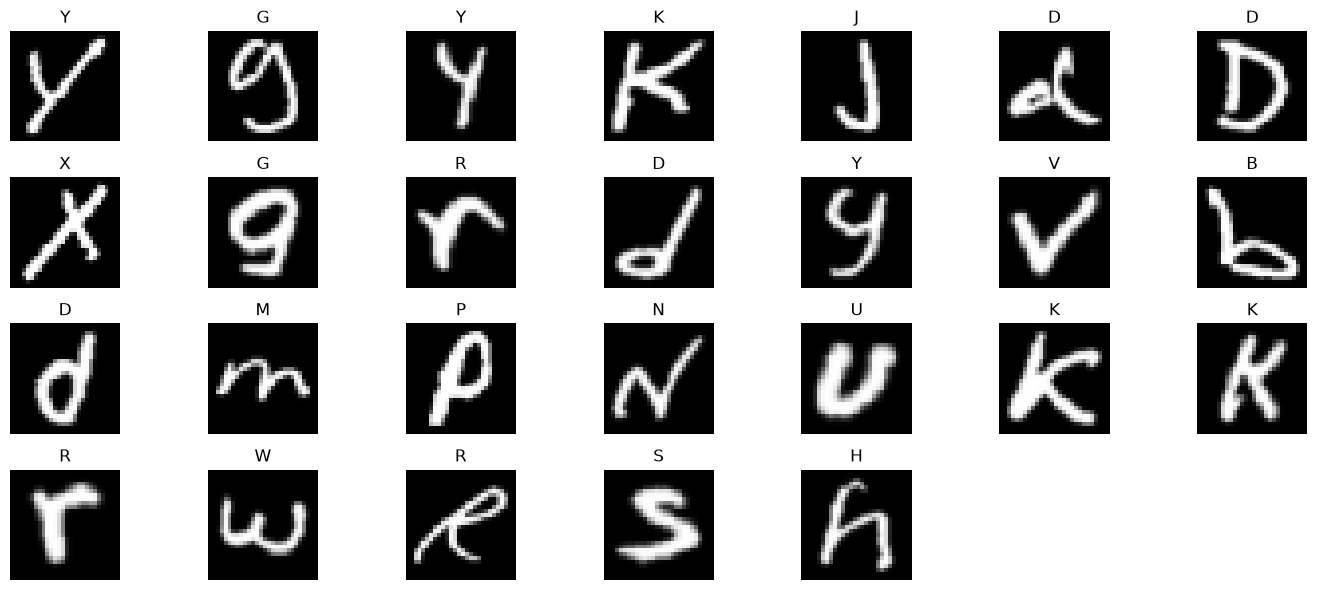

In [6]:
X_letters = []
y_letters = []

for image, label in tfds.as_numpy(ds_train.take(26)):
    X_letters.append(image.squeeze().T)   # .T = orientation theek karna
    y_letters.append(label)

letters = string.ascii_uppercase   # 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'

plt.figure(figsize=(14, 6))
for i in range(26):
    plt.subplot(4, 7, i + 1)
    plt.imshow(X_letters[i], cmap='gray')
    plt.title(letters[y_letters[i] - 1])
    plt.axis('off')

plt.tight_layout()
plt.show()

## Step 5: Poora letters data numpy array me lana
**Kya hua:**
- `ds.batch(n)` se poora dataset ek hi baar me array bana diya
- Images ko `transpose` karke seedha kiya
- Labels 1–26 the. Hum digits (0–9) ke baad letters rakhenge, isliye letters ka label **10–35** kar diya

In [7]:
def ds_to_numpy(ds, n):
    x, y = next(iter(tfds.as_numpy(ds.batch(n))))
    return x, y

x_train_l, y_train_l = ds_to_numpy(ds_train, info.splits['train'].num_examples)
x_test_l,  y_test_l  = ds_to_numpy(ds_test,  info.splits['test'].num_examples)

# Orientation theek karna: (N, 28, 28, 1) me height-width swap
x_train_l = x_train_l.transpose(0, 2, 1, 3)
x_test_l  = x_test_l.transpose(0, 2, 1, 3)

print("Label range (pehle):", y_train_l.min(), "se", y_train_l.max())   # 1 se 26

# Labels: 1-26 -> 10-35 (digits 0-9 ke baad)
y_train_l = y_train_l + 9
y_test_l  = y_test_l + 9

print("Label range (baad me):", y_train_l.min(), "se", y_train_l.max())  # 10 se 35
print("Letters train:", x_train_l.shape, "| test:", x_test_l.shape)

Label range (pehle): 1 se 26
Label range (baad me): 10 se 35
Letters train: (88800, 28, 28, 1) | test: (14800, 28, 28, 1)


# PART C: Digits + Letters ko milana

## Step 6: Dono datasets ko ek karna (36 classes)
**Kya hua:**
- Digits ko (N, 28, 28, 1) shape me kiya
- Digits aur letters ko `concatenate` se jod diya
- **Class names:** `0-9` + `A-Z` = 36 classes
- **Normalize:** pixels 0–255 se 0–1
- **Shuffle:** train data ko mix kiya (warna validation me sirf letters aa jate, kyunki wo end me hain)

In [8]:
class_names = list("0123456789") + list(string.ascii_uppercase)   # 36 classes
NUM_CLASSES = len(class_names)

# Digits ko 4D banana
x_train_d = x_train_d.reshape(-1, 28, 28, 1)
x_test_d  = x_test_d.reshape(-1, 28, 28, 1)

# Dono ko jodna
x_train = np.concatenate([x_train_d, x_train_l]).astype("float32") / 255.0
y_train = np.concatenate([y_train_d, y_train_l]).astype("int64")
x_test  = np.concatenate([x_test_d, x_test_l]).astype("float32") / 255.0
y_test  = np.concatenate([y_test_d, y_test_l]).astype("int64")

# Train data shuffle karna
rng = np.random.default_rng(42)
perm = rng.permutation(len(x_train))
x_train, y_train = x_train[perm], y_train[perm]

print("Train:", x_train.shape, "| Test:", x_test.shape)
print("Total classes:", NUM_CLASSES)

Train: (148800, 28, 28, 1) | Test: (24800, 28, 28, 1)
Total classes: 36


## Step 7: Mila hua data dekhna
**Kya hua:** 36 random images dikhayi (digits + letters dono). Title me asli label hai.

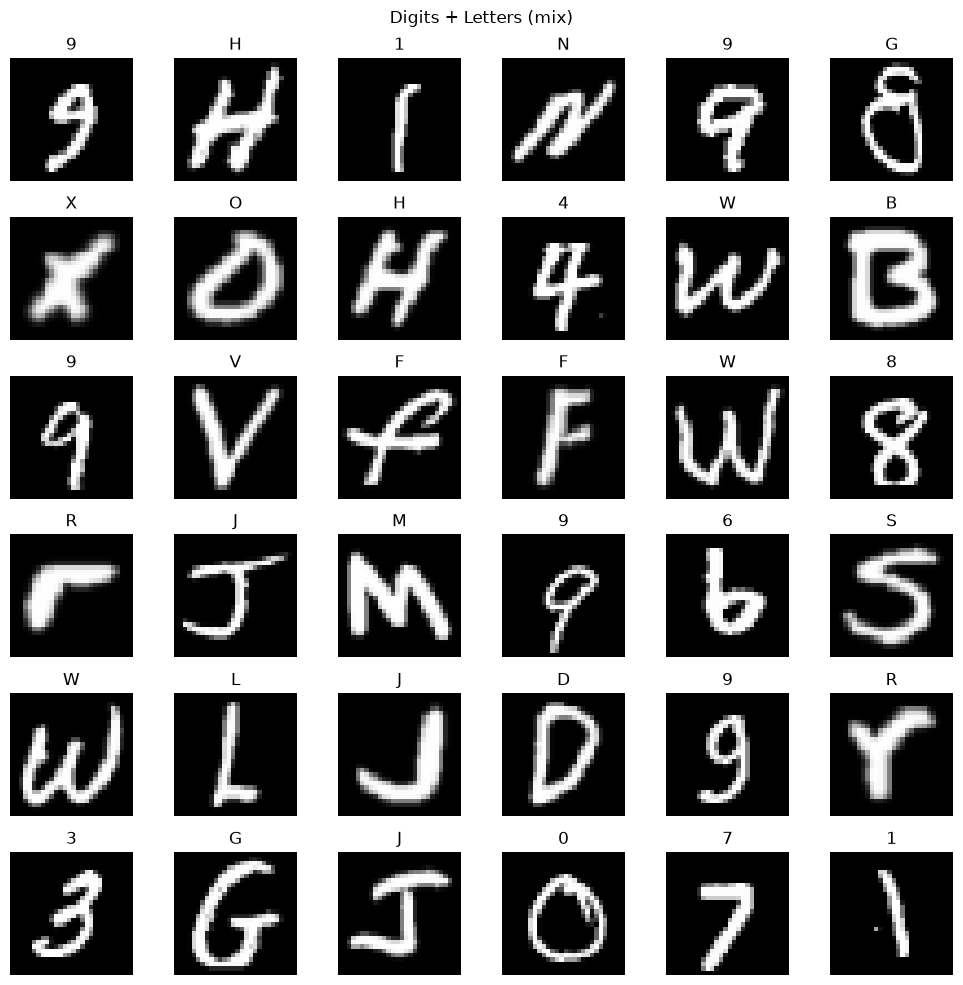

In [9]:
idx = np.random.choice(len(x_train), 36, replace=False)

plt.figure(figsize=(10, 10))
for i, k in enumerate(idx):
    plt.subplot(6, 6, i + 1)
    plt.imshow(x_train[k].reshape(28, 28), cmap="gray")
    plt.title(class_names[y_train[k]])
    plt.axis("off")
plt.suptitle("Digits + Letters (mix)")
plt.tight_layout()
plt.show()

## Step 8: Har class ki count
**Kya hua:** Dekha ki har class me kitni images hain. Letters ki images har class me ~4,800 hain, digits ki ~6,000 ke aaspaas, yaani data kaafi balanced hai.

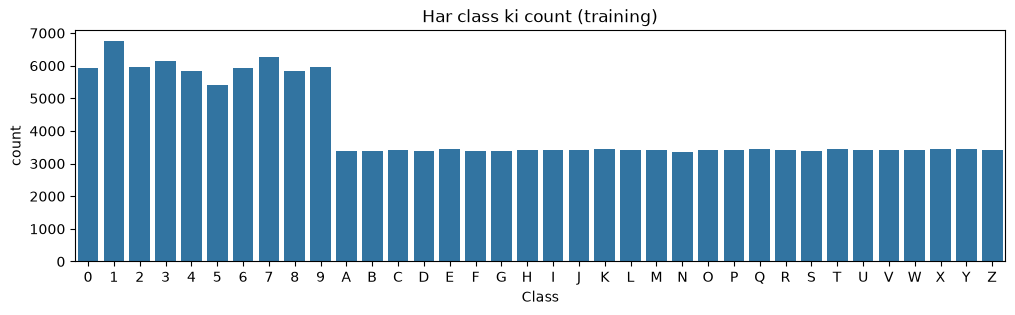

In [10]:
plt.figure(figsize=(12, 3))
sns.countplot(x=[class_names[i] for i in y_train], order=class_names)
plt.title("Har class ki count (training)")
plt.xlabel("Class")
plt.show()

## Step 9: CNN model banana
**Kya hua:** Ek CNN banaya jo 36 classes me se ek chunta hai.

Layers ka matlab (presentation ke liye):
- **Conv2D** = chhota filter image pe ghoom ke edges/curves dhoondta hai
- **MaxPooling** = image chhoti karta hai, sirf important cheez rakhta hai
- **Flatten** = 2D ko ek lambi line (1D) bana deta hai
- **Dropout** = kuch neurons randomly band karta hai, taaki model ratta na maare
- **Dense + Softmax** = final decision, 36 classes ki probability
- **RandomRotation/Zoom/Translation** = training me image thodi tedhi/zoom/shift hoti hai, isse webcam pe model better chalta hai

In [11]:
def build_cnn(num_classes):
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),

        # Augmentation (sirf training me active hota hai)
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.1, 0.1),

        # Feature extraction
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        # Classification
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(256, activation="relu"),
        layers.Dense(num_classes, activation="softmax"),
    ])
    return model

model = build_cnn(NUM_CLASSES)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       409,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         9,252 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 437,924 (1.67 MB)

 Trainable params: 437,924 (1.67 MB)

 Non-trainable params: 0 (0.00 B)

## Step 10: Model compile aur train karna
**Kya hua:**
- **Optimizer (Adam):** model ko seekhne ka tareeka
- **Loss:** galti naapne ka formula
- **Epoch:** poora data model ko ek baar dikhana (yahan 10 baar)
- **validation_split=0.1:** 10% data check karne ke liye alag

**Time:** CPU pe thoda time lag sakta hai (data 1.8 lakh images se zyada hai).

In [12]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1,
)

checkpoint = ModelCheckpoint(
    filepath="best_char_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1,
)

In [13]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history = model.fit(
    x_train, y_train,
    epochs=6,
    batch_size=128,
    validation_split=0.1,
)

Epoch 1/6
1047/1047 ━━━━━━━━━━━━━━━━━━━━ 66s 60ms/step - accuracy: 0.6417 - loss: 1.2108 - val_accuracy: 0.8551 - val_loss: 0.4230
Epoch 2/6
1047/1047 ━━━━━━━━━━━━━━━━━━━━ 55s 53ms/step - accuracy: 0.7918 - loss: 0.6585 - val_accuracy: 0.8669 - val_loss: 0.4107
Epoch 3/6
1047/1047 ━━━━━━━━━━━━━━━━━━━━ 58s 55ms/step - accuracy: 0.8261 - loss: 0.5386 - val_accuracy: 0.8718 - val_loss: 0.3883
Epoch 4/6
1047/1047 ━━━━━━━━━━━━━━━━━━━━ 53s 51ms/step - accuracy: 0.8434 - loss: 0.4812 - val_accuracy: 0.8630 - val_loss: 0.4299
Epoch 5/6
1047/1047 ━━━━━━━━━━━━━━━━━━━━ 54s 52ms/step - accuracy: 0.8550 - loss: 0.4437 - val_accuracy: 0.8806 - val_loss: 0.3823
Epoch 6/6
1047/1047 ━━━━━━━━━━━━━━━━━━━━ 53s 51ms/step - accuracy: 0.8622 - loss: 0.4188 - val_accuracy: 0.8747 - val_loss: 0.4041


## Step 11: Training ka graph
**Kya hua:** Accuracy upar jani chahiye, loss neeche. Train aur validation line paas paas ho to model sahi seekh raha hai.

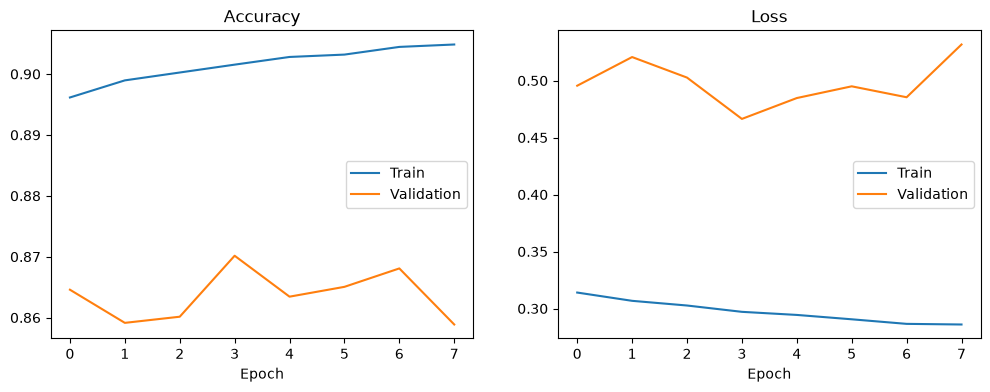

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history["accuracy"], label="Train")
ax[0].plot(history.history["val_accuracy"], label="Validation")
ax[0].set_title("Accuracy")
ax[0].set_xlabel("Epoch")
ax[0].legend()

ax[1].plot(history.history["loss"], label="Train")
ax[1].plot(history.history["val_loss"], label="Validation")
ax[1].set_title("Loss")
ax[1].set_xlabel("Epoch")
ax[1].legend()

plt.show()

## Step 12: Test accuracy (overall, digits aur letters alag)
**Kya hua:** Test data (jo model ne kabhi nahi dekha) pe accuracy nikali. Saath me digits aur letters ki accuracy alag-alag bhi dekhi.
- Digits ~98-99%, Letters ~90-93% normal hai (letters mushkil hote hain)

In [27]:
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

overall = (y_pred == y_test).mean()
is_digit = y_test < 10

print(f"Overall Accuracy : {overall * 100:.2f}%")
print(f"Digits  Accuracy : {(y_pred[is_digit] == y_test[is_digit]).mean() * 100:.2f}%")
print(f"Letters Accuracy : {(y_pred[~is_digit] == y_test[~is_digit]).mean() * 100:.2f}%")

Overall Accuracy : 84.78%
Digits  Accuracy : 98.41%
Letters Accuracy : 75.57%


## Step 13: Confusion Matrix aur sabse zyada confuse hone wale jodi
**Kya hua:** Heatmap dikhata hai model kaunsi class ko kis class se confuse karta hai (diagonal jitni gehri, utna accha).
Neeche top-5 galtiyan print hongi. Aksar **0 vs O**, **1 vs I**, **5 vs S** jaise jodi milte hain, kyunki wo dikhte ek jaise hain.

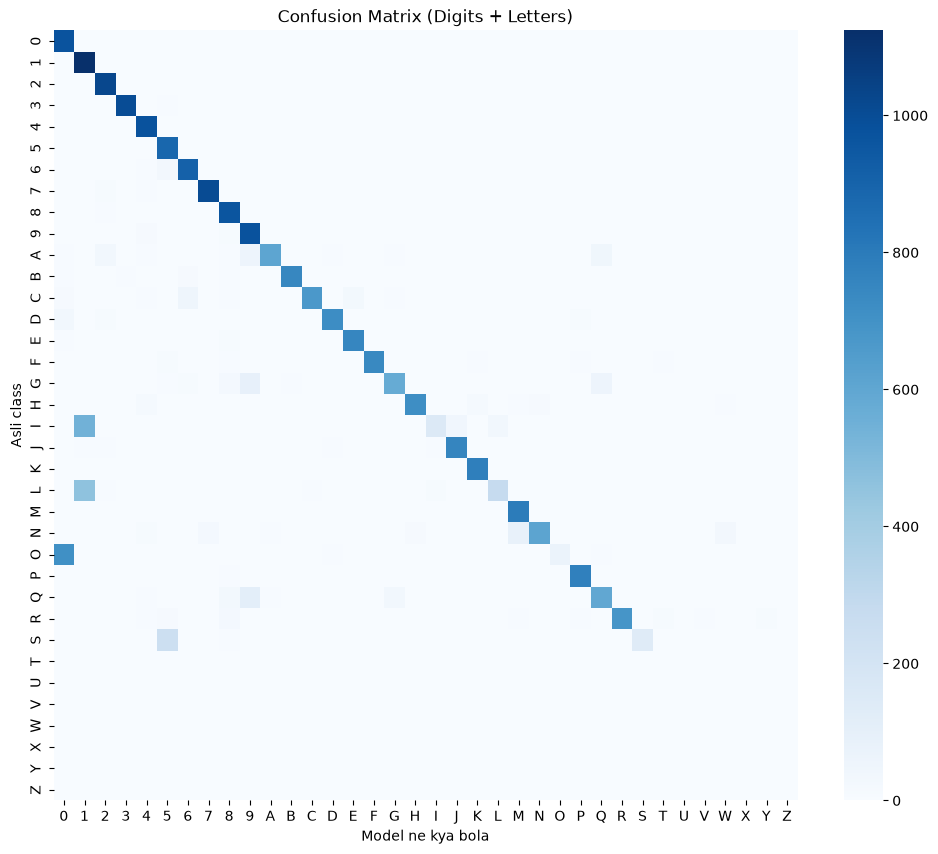

Sabse zyada confusion:
  Asli 'O' ko model ne '0' bola: 709 baar
  Asli 'I' ko model ne '1' bola: 546 baar
  Asli 'L' ko model ne '1' bola: 465 baar
  Asli 'S' ko model ne '5' bola: 247 baar
  Asli 'Q' ko model ne '9' bola: 114 baar


In [28]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Model ne kya bola")
plt.ylabel("Asli class")
plt.title("Confusion Matrix (Digits + Letters)")
plt.show()

# Sabse zyada confuse hone wale 5 jodi
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
top = np.argsort(cm_off.ravel())[::-1][:5]
print("Sabse zyada confusion:")
for t in top:
    a, b = np.unravel_index(t, cm_off.shape)
    print(f"  Asli '{class_names[a]}' ko model ne '{class_names[b]}' bola: {cm_off[a, b]} baar")

## Step 14: Kuch predictions dekhna
**Kya hua:** 20 random test images pe prediction. Green = sahi, Red = galat.

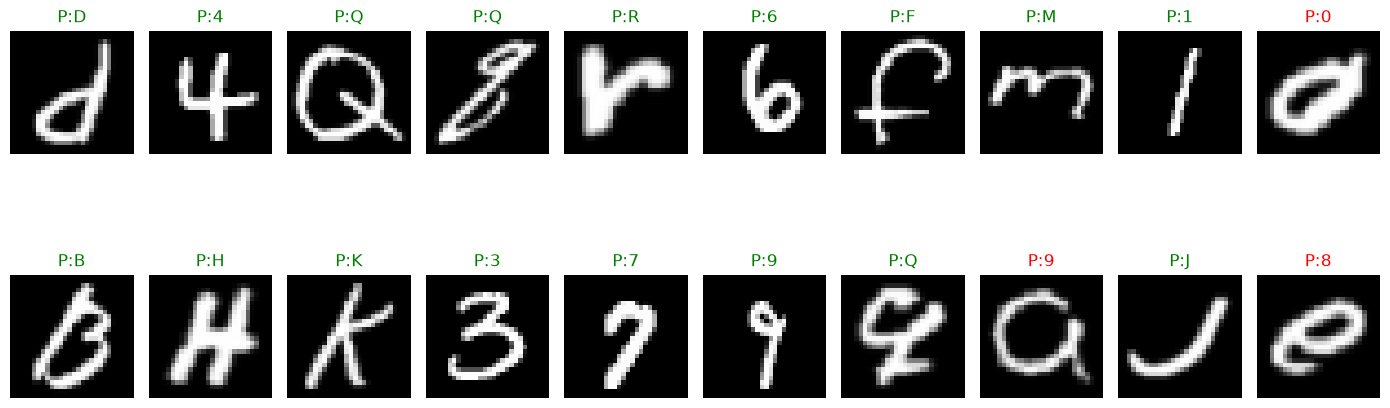

In [29]:
idx = np.random.choice(len(x_test), 20, replace=False)

plt.figure(figsize=(14, 6))
for i, k in enumerate(idx):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[k].reshape(28, 28), cmap="gray")
    ok = y_pred[k] == y_test[k]
    plt.title(f"P:{class_names[y_pred[k]]}", color="green" if ok else "red")
    plt.axis("off")
plt.tight_layout()
plt.show()

## Step 15: Model save karna
**Kya hua:** Model file me save kiya, taaki webcam demo me dobara train na karna pade. (Kabhi bhi `load_model` se wapas la sakte ho.)

In [30]:
model.save("digit_letter_model.keras")
print("digit_letter_model.keras save ho gaya")

digit_letter_model.keras save ho gaya


# PART D: Live Webcam Demo

## Step 16: Webcam image ko model ke format me badalne wala function
**Kya hua:** Webcam ki image EMNIST/MNIST jaisi nahi hoti, isliye usse waisa banana padta hai:
1. Grayscale karo
2. Blur karo (noise kam)
3. **Threshold:** kaagaz safed, likhawat kali, usse ulta karke likhawat safed + background kala (MNIST jaisa)
4. Likhawat ko crop karke center me lao, 20x20 karo, aur 4-4 pixel ka kala border lagao (total 28x28)

In [31]:
import cv2

def preprocess_roi(roi):
    gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (5, 5), 0)

    # Likhawat safed, background kala
    _, th = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # Chhota noise hatana
    kernel = np.ones((3, 3), np.uint8)
    th = cv2.morphologyEx(th, cv2.MORPH_OPEN, kernel)

    # Kuch likha hi nahi hai to skip
    if cv2.countNonZero(th) < 150:
        return None, th

    # Likhawat ko crop karna
    x, y, w, h = cv2.boundingRect(cv2.findNonZero(th))
    crop = th[y:y + h, x:x + w]

    # Square canvas ke center me rakhna
    s = max(w, h)
    square = np.zeros((s, s), np.uint8)
    square[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = crop

    # 20x20 karke 4-4 pixel border = 28x28
    small = cv2.resize(square, (20, 20), interpolation=cv2.INTER_AREA)
    img28 = np.pad(small, 4)

    model_input = (img28.astype("float32") / 255.0).reshape(1, 28, 28, 1)
    return model_input, img28

## Step 17: Live webcam loop
**Kya hua:** Webcam khulta hai, beech me ek hara box dikhta hai. Safed kaagaz pe **kala marker (mota)** se digit ya letter likho aur box ke andar dikhao. Model khud pehchanega ki digit hai ya letter. Box ke neeche doosre aur teesre guess bhi dikhte hain.

**Key:** `q` = band karna

**Tips:** Acchi roshni rakho, mota likho, ek baar me ek hi character. Capital letters likho. Alag chhoti window me wo 28x28 image dikhti hai jo model asal me dekh raha hai.

In [33]:
model = keras.models.load_model("digit_letter_model.keras")

cap = cv2.VideoCapture(0)
BOX = 250

while True:
    ret, frame = cap.read()
    if not ret:
        print("Webcam nahi mila")
        break

    h, w = frame.shape[:2]
    x1, y1 = w // 2 - BOX // 2, h // 2 - BOX // 2
    x2, y2 = x1 + BOX, y1 + BOX

    roi = frame[y1:y2, x1:x2]
    model_input, view = preprocess_roi(roi)

    text, alt = "Kuch likho...", ""
    if model_input is not None:
        probs = model.predict(model_input, verbose=0)[0]
        top3 = np.argsort(probs)[::-1][:3]
        text = f"{class_names[top3[0]]}  ({probs[top3[0]] * 100:.0f}%)"
        alt = "Other: " + "  ".join(f"{class_names[k]}:{probs[k] * 100:.0f}%" for k in top3[1:])

    cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(frame, "q = quit", (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 0), 2)
    cv2.putText(frame, text, (x1, y1 - 15),
                cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 0), 3)
    cv2.putText(frame, alt, (x1, y2 + 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2)

    cv2.imshow("Live OCR Demo", frame)
    cv2.imshow("Model ne ye dekha (28x28)",
               cv2.resize(view, (200, 200), interpolation=cv2.INTER_NEAREST))

    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()

# 🎤 Presentation ke liye Summary

**Problem:** Haath se likhe digits aur letters ko computer se padhwana (OCR).

**Data:** MNIST (70,000 digit images) + EMNIST Letters (~145,000 letter images) = 36 classes (0–9, A–Z).

**Model (CNN) ka flow:**
`Image → Conv (edges dhoondo) → Pool (chhota karo) → Conv → Pool → Flatten → Dense → Softmax (36 probabilities)`

**Khaas baat:** Ek hi model digits aur letters dono padhta hai, alag mode ki zarurat nahi.

**Result:** Digits ~98–99%, Letters ~90–93% accuracy.

**Demo:** Webcam se live kaagaz pe likha hua padhna.

**Limitations / Future work:**
- **0 vs O, 1 vs I, 5 vs S** jaise similar shapes confuse hote hain (confusion matrix me dikhta hai)
- Ek baar me ek hi character padhta hai (poora word nahi)
- Roshni aur likhne ka style asar karta hai
- Aage: poore words ke liye CRNN/OCR, ya mobile app